# 22 Is there anything for a second pathway to add? Diagnostics before building a hybrid

**Why this notebook.** Notebooks 18 to 21 found nothing that improves the ST-GCN by changing its backbone, loss, head or
initial weights. A hybrid that combines the ST-GCN with a different kind of model is only worth building if the
other kind of model gets right some of what the ST-GCN gets wrong. This notebook measures that, using validation
data only, before any hybrid is designed.

**The question, made precise.** For the validation clips an ST-GCN gets wrong, how often does another model get them
right (its *rescue rate*)? That number is meaningless alone, because two ST-GCNs trained with different seeds also
disagree on some clips. So every rescue rate is set against a **control**: the rescue rate of a second ST-GCN trained with
another seed. A second pathway is only informative to the extent its rescue rate exceeds the control's.

**Part A, no training.** The reporting-seed models already trained (ST-GCN, LSTM, Transformer, ST-TR, advanced
augmentation) are compared on their saved *validation* predictions. This asks whether any of the existing
architectures is more complementary to the ST-GCN than another ST-GCN seed is.

**Part B, six short LSTM runs.** Three bidirectional LSTMs, trained on tuning seeds 77 and 88 so that they pair with the
stage 1 ST-GCN-with-velocity runs on the same seeds:

| variant | per joint input | question |
|---|---|---|
| `pose` | x, y, confidence, bone, court position (the baseline LSTM input) | the sequence model as before |
| `motion` | smoothed velocity only, no positions | does motion alone carry usable information, and does it overlap less with what the ST-GCN knows? |
| `pose_motion` | both | the candidate input for a sequence pathway |

**Decision rule, fixed before running.** A sequence pathway is justified if the best LSTM variant's rescue rate on the
ST-GCN's errors is at least 5 points above the same-architecture control, and the 95% interval of that paired
difference (bootstrap over the error clips) excludes zero. If not, a hybrid that adds a sequence model to the
ST-GCN has no complementary signal to exploit, and the next design should look elsewhere. The 5 point margin is a
judgement, chosen as roughly twice the typical difference between two seeds; with about 360 error clips the interval
is wide, so a pass is evidence to build and test, not proof that a hybrid will help.

**Not used.** Clip duration is deliberately excluded. Models see only the pose sequence.

Logs to `BadmintonPoseAnalysis/experiments/hybrid_diagnostics`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import glob
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import lstm as lstm_model
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/hybrid_diagnostics"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/hybrid_diagnostics"
STAGE1_OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
os.makedirs(OUT, exist_ok=True)

TUNING_SEEDS, REPORTING_SEEDS = [77, 88], [42, 123, 7]
SPLITS = ("train", "val")          # the test set is never used here
NORMALISATION = "body"
NUM_WORKERS, EVAL_WORKERS = 20, 8
N_BOOT, MIN_MARGIN = 2000, 0.05
VARIANTS = ["pose", "motion", "pose_motion"]
FEATURES = {"pose": 7, "motion": 2, "pose_motion": 9}        # channels per joint

# the LSTM recipe of notebook 09
RECIPE = {"model": "LSTM", "hidden_size": 256, "num_layers": 2, "dropout": 0.3, "min_native_frames": 5,
          "batch_size": 32, "lr": 1e-3, "weight_decay": 1e-4, "label_smoothing": 0.0, "num_epochs": 60,
          "patience": 15, "select_metric": "top1", "target_per_class": 300, "augmentation": "advanced"}

with open(f"{REPO}/configs/model5_stage1.json") as f:
    VEL_SCALE = json.load(f)["velocity_scale"]
rng = np.random.RandomState(0)

In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]


def load_val(path):
    d = pd.read_csv(path)
    d = d[d["split"] == "val"].sort_values("filepath").reset_index(drop=True)
    return d["filepath"].to_numpy(), d["label"].map(class_to_id).to_numpy(), d["pred"].map(class_to_id).to_numpy()


def make_forward(variant):
    def forward(model, batch, device):
        parts = []
        if variant in ("pose", "pose_motion"):
            parts += [batch["keypoints"], batch["bone"], batch["court"][:, :, None, :].expand(-1, -1, ds.NUM_JOINTS, -1)]
        if variant in ("motion", "pose_motion"):
            parts.append(stgcn_model.smoothed_velocity(batch["keypoints"][..., :2].float()) * VEL_SCALE)
        x = torch.cat(parts, dim=-1).float()
        n, t, v, c = x.shape
        return model(x.reshape(n, t, v * c).to(device, non_blocking=True))
    return forward


def paired_rescue(anchor, challenger, control, labels, triples):
    """
    anchor, challenger, control: dict seed -> predictions on the same validation clips.
    triples: (anchor seed, challenger seed, control seed). On every clip the anchor gets wrong, compares whether the
    challenger gets it right with whether the control (a second run of the anchor's architecture) does.
    """
    r_ch, r_ct, acc_a, uni_ch, uni_ct = [], [], [], [], []
    for a, c, k in triples:
        wrong = anchor[a] != labels
        r_ch.append((challenger[c] == labels)[wrong])
        r_ct.append((control[k] == labels)[wrong])
        acc_a.append((anchor[a] == labels).mean())
        uni_ch.append(((anchor[a] == labels) | (challenger[c] == labels)).mean())
        uni_ct.append(((anchor[a] == labels) | (control[k] == labels)).mean())
    r_ch, r_ct = np.concatenate(r_ch).astype(float), np.concatenate(r_ct).astype(float)
    diff = r_ch - r_ct
    boots = [diff[rng.randint(0, len(diff), len(diff))].mean() for _ in range(N_BOOT)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"error clips": len(diff), "rescue rate": r_ch.mean(), "control rescue rate": r_ct.mean(),
            "difference": diff.mean(), "ci_lo": lo, "ci_hi": hi,
            "anchor accuracy": np.mean(acc_a), "union accuracy": np.mean(uni_ch), "control union accuracy": np.mean(uni_ct)}

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Part A: existing architectures, saved validation predictions

Anchor: the ST-GCN (advanced augmentation, `body_court`, no velocity). Challengers: LSTM, Transformer and ST-TR, same
seed. Control: the ST-GCN of the next seed in the cycle. All on validation clips only.

In [4]:
RUN_RE = re.compile(r"^(stgcn|lstm|transformer|sttr)_advanced_s(\d+)$")
found = {}
for p in glob.glob(f"{OUTPUTS}/models/**/*_predictions.csv", recursive=True):
    m = RUN_RE.match(os.path.basename(p).replace("_predictions.csv", ""))
    if m and int(m.group(2)) in REPORTING_SEEDS:
        found.setdefault(m.group(1), {})[int(m.group(2))] = p
assert all(sorted(found.get(m, {})) == sorted(REPORTING_SEEDS) for m in ("stgcn", "lstm", "transformer", "sttr")), \
    {m: sorted(v) for m, v in found.items()}

files_a, labels_a = None, None
pred_a = {}
for model, seeds in found.items():
    pred_a[model] = {}
    for s, p in seeds.items():
        f, y, yh = load_val(p)
        if files_a is None:
            files_a, labels_a = f, y
        assert (f == files_a).all() and (y == labels_a).all(), f"clip order differs for {model} seed {s}"
        pred_a[model][s] = yh
cycle = {s: REPORTING_SEEDS[(i + 1) % len(REPORTING_SEEDS)] for i, s in enumerate(REPORTING_SEEDS)}
triples_a = [(s, s, cycle[s]) for s in REPORTING_SEEDS]

rows_a = []
for model, label in (("stgcn", "ST-GCN, other seed (control)"), ("lstm", "LSTM"), ("transformer", "Transformer"), ("sttr", "ST-TR")):
    r = paired_rescue(pred_a["stgcn"], pred_a[model], pred_a["stgcn"], labels_a, triples_a)
    rows_a.append({"challenger": label, **r})
part_a = pd.DataFrame(rows_a)
part_a_show = pd.DataFrame({
    "challenger": part_a["challenger"],
    "rescues ST-GCN errors (%)": (100 * part_a["rescue rate"]).round(1),
    "control (%)": (100 * part_a["control rescue rate"]).round(1),
    "difference (points)": (100 * part_a["difference"]).round(1),
    "95% CI": [f"[{100 * a:+.1f}, {100 * b:+.1f}]" for a, b in zip(part_a["ci_lo"], part_a["ci_hi"])],
    "ST-GCN val accuracy (%)": (100 * part_a["anchor accuracy"]).round(1),
    "union with challenger (%)": (100 * part_a["union accuracy"]).round(1)})
print(f"{part_a['error clips'].iloc[0]} ST-GCN error clips pooled over {len(REPORTING_SEEDS)} seeds, {len(labels_a)} validation clips")
part_a_show

591 ST-GCN error clips pooled over 3 seeds, 781 validation clips


,challenger,rescues ST-GCN errors (%),control (%),difference (points),95% CI,ST-GCN val accuracy (%),union with challenger (%)
0,"ST-GCN, other seed (control)",0.0,18.1,-18.1,"[-21.3, -15.2]",74.8,74.8
1,LSTM,23.0,18.1,4.9,"[+1.0, +8.8]",74.8,80.6
2,Transformer,22.8,18.1,4.7,"[+0.8, +8.5]",74.8,80.5
3,ST-TR,25.7,18.1,7.6,"[+3.9, +11.7]",74.8,81.3


## Part B: motion-only and pose-plus-motion LSTMs, paired with the ST-GCN-with-velocity runs

Smoke test first: shapes, a gradient through every variant, matching velocity statistics between augmented training
and clean validation clips (the motion variant depends on nothing else), and the stage 1 ST-GCN predictions needed for
the pairing.

In [5]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
batch = next(iter(loaders["train"]))
rows = []
for variant in VARIANTS:
    in_features = ds.NUM_JOINTS * FEATURES[variant]
    model = lstm_model.build_lstm(in_features, K, RECIPE["hidden_size"], RECIPE["num_layers"], RECIPE["dropout"]).to(device)
    logits = make_forward(variant)(model, batch, device)
    assert logits.shape == (RECIPE["batch_size"], K)
    nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
    assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
    rows.append({"variant": variant, "features per frame": in_features, "parameters": sum(p.numel() for p in model.parameters())})
    del model
print(pd.DataFrame(rows).to_string(index=False))

val_xy = ds.BadmintonPoseDataset(manifest[manifest["split"] == "val"].head(200), KEYPOINTS, class_to_id, "none", NORMALISATION)
vel_val = stgcn_model.smoothed_velocity(torch.stack([val_xy[i]["keypoints"][..., :2] for i in range(len(val_xy))])) * VEL_SCALE
vel_train = stgcn_model.smoothed_velocity(batch["keypoints"][..., :2].float()) * VEL_SCALE
ratio = float(vel_train.std() / vel_val.std())
print(f"velocity std, augmented training batch {vel_train.std():.2f} vs clean validation clips {vel_val.std():.2f} (ratio {ratio:.2f})")
assert 0.7 < ratio < 1.4

pred_b = {}
files_b = labels_b = None
for s in TUNING_SEEDS:
    f, y, yh = load_val(f"{STAGE1_OUT}/model5s1_control_s{s}/model5s1_control_s{s}_predictions.csv")
    files_b, labels_b = (f, y) if files_b is None else (files_b, labels_b)
    assert (f == files_b).all()
    pred_b[s] = yh
assert (files_b == files_a).all(), "validation clips differ between the stage 1 runs and the reporting runs"
del loaders
print("smoke test passed; ST-GCN with velocity, validation top1 per seed:", {s: round(float((pred_b[s] == labels_b).mean()), 4) for s in TUNING_SEEDS})

    variant  features per frame  parameters
       pose                 119     2359314
     motion                  34     2185234
pose_motion                 153     2428946
velocity std, augmented training batch 1.04 vs clean validation clips 0.91 (ratio 1.15)
smoke test passed; ST-GCN with velocity, validation top1 per seed: {77: 0.7644, 88: 0.7708}


In [6]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])

for variant in VARIANTS:
    for seed in TUNING_SEEDS:
        if ((done["config"] == variant) & (done["seed"] == seed)).any():
            print(f"skip {variant} seed {seed}, already done")
            continue
        run_name = f"lstm_{variant}_s{seed}"
        print(f"\n=== {run_name} ===")
        tr.seed_everything(seed)
        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["hybrid_diagnostics", "lstm", variant, f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, "variant": variant, "features_per_joint": FEATURES[variant], "velocity_scale": VEL_SCALE,
                      "seed": seed, "keypoints": KEYPOINTS, "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})
        loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                                   batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                                   num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
        forward = make_forward(variant)
        model = lstm_model.build_lstm(ds.NUM_JOINTS * FEATURES[variant], K, RECIPE["hidden_size"],
                                      RECIPE["num_layers"], RECIPE["dropout"]).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=RECIPE["lr"], weight_decay=RECIPE["weight_decay"])
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=RECIPE["num_epochs"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])
        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE["patience"], select_metric=RECIPE["select_metric"],
                                                splits=SPLITS, grad_clip=5.0)
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                                extra={"config": variant, "seed": seed})
        task.close()
        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()


=== lstm_pose_s77 ===
ClearML Task: created new task id=df299acf45e04589bfb89f8318112dec
2026-10-08 00:17:49,441 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/4071485982454df2accc91707cce9c9b/tasks/df299acf45e04589bfb89f8318112dec/output/log
epoch   0  loss 1.924  train 0.500  val 0.508 (mca 0.455)  *
epoch   1  loss 1.402  train 0.591  val 0.593 (mca 0.546)  *
epoch   2  loss 1.231  train 0.666  val 0.654 (mca 0.536)  *
epoch   4  loss 1.018  train 0.707  val 0.680 (mca 0.581)  *
epoch   5  loss 0.971  train 0.745  val 0.681 (mca 0.609)  *
epoch   6  loss 0.872  train 0.753  val 0.697 (mca 0.618)  *
epoch   8  loss 0.758  train 0.777  val 0.704 (mca 0.617)  *
epoch  10  loss 0.648  train 0.804  val 0.685 (mca 0.615)
epoch  15  loss 0.419  train 0.891  val 0.702 (mca 0.619)
epoch  16  loss 0.375  train 0.898  val 0.707 (mca 0.608)  *
epoch  17  loss 0.351  train 0.895  val 0.714 (mca 0.618)  *


██████████████████████████████████ 100% | 9.00/9.0 MB [00:02<00:00,  4.43MB/s]: 



=== lstm_pose_s88 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=5c24e48764ab4285b4d6f0224f2c6fc5
ClearML results page: https://app.clear.ml/projects/4071485982454df2accc91707cce9c9b/tasks/5c24e48764ab4285b4d6f0224f2c6fc5/output/log
epoch   0  loss 1.960  train 0.569  val 0.588 (mca 0.438)  *
epoch   2  loss 1.213  train 0.676  val 0.649 (mca 0.557)  *
epoch   3  loss 1.135  train 0.686  val 0.654 (mca 0.541)  *
epoch   4  loss 1.023  train 0.710  val 0.677 (mca 0.614)  *
epoch   5  loss 0.940  train 0.720  val 0.665 (mca 0.601)
epoch   6  loss 0.874  train 0.755  val 0.700 (mca 0.626)  *
epoch  10  loss 0.640  train 0.809  val 0.694 (mca 0.612)
epoch  15  loss 0.424  train 0.884  val 0.677 (mca 0.607)
epoch  18  loss 0.322  train 0.909  val 0.716 (mca 0.614)  *
epoch  20  loss 0.267  train 0.942  val 0.711 (mca 0.600)
epoch  25  loss 0.165  train 0.969  val 0.718 (mca 0.616)  *
epoch  30  loss 0.087  train 0.992  val 0.711 (mca 0.606)
epoch  33  loss 0.065  train 0.993  val 0.720 (mca 0.611)  *
epoch  35  loss 0.04

...

█████████████████████████████████ 100% | 9.27/9.27 MB [00:02<00:00,  3.94MB/s]: 



=== lstm_pose_motion_s88 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=4bba3b02b3994fd48441b3bdf1cbaa16
ClearML results page: https://app.clear.ml/projects/4071485982454df2accc91707cce9c9b/tasks/4bba3b02b3994fd48441b3bdf1cbaa16/output/log
epoch   0  loss 1.749  train 0.600  val 0.609 (mca 0.538)  *
epoch   2  loss 1.026  train 0.744  val 0.695 (mca 0.606)  *
epoch   5  loss 0.705  train 0.815  val 0.663 (mca 0.541)
epoch  10  loss 0.372  train 0.903  val 0.675 (mca 0.590)
epoch  15  loss 0.223  train 0.949  val 0.676 (mca 0.572)
early stop at epoch 17, best val top1 0.6953 at epoch 2
train top1 0.7440 mca 0.6906 | val top1 0.6953 mca 0.6061


█████████████████████████████████ 100% | 9.27/9.27 MB [00:02<00:00,  4.63MB/s]: 


In [7]:
res = pd.read_csv(results_path)
g = res.groupby("config")
accuracy_b = pd.DataFrame({"val top1": 100 * g["val_top1"].mean(), "val mca": 100 * g["val_mca"].mean(),
                           "val top5": 100 * g["val_top5"].mean(), "best epoch": g["best_epoch"].mean()}).loc[VARIANTS].round(2)
accuracy_b.loc["ST-GCN + velocity (stage 1 control)"] = [100 * np.mean([(pred_b[s] == labels_b).mean() for s in TUNING_SEEDS]),
                                                        np.nan, np.nan, np.nan]
accuracy_b

,val top1,val mca,val top5,best epoch
config,,,,
pose,72.470000,61.96,93.85,34.0
motion,69.650000,56.81,92.38,35.0
pose_motion,70.230000,61.23,93.66,10.5
ST-GCN + velocity (stage 1 control),76.760563,NaN,NaN,NaN


In [8]:
other = {s: [t for t in TUNING_SEEDS if t != s][0] for s in TUNING_SEEDS}
triples_b = [(s, s, other[s]) for s in TUNING_SEEDS]
rows_b = []
lstm_pred = {}
for variant in VARIANTS:
    lstm_pred[variant] = {}
    for s in TUNING_SEEDS:
        f, y, yh = load_val(f"{OUT}/lstm_{variant}_s{s}/lstm_{variant}_s{s}_predictions.csv")
        assert (f == files_b).all() and (y == labels_b).all()
        lstm_pred[variant][s] = yh
    rows_b.append({"challenger": f"LSTM {variant}", **paired_rescue(pred_b, lstm_pred[variant], pred_b, labels_b, triples_b)})
part_b = pd.DataFrame(rows_b)
part_b_show = pd.DataFrame({
    "challenger": part_b["challenger"],
    "rescues ST-GCN errors (%)": (100 * part_b["rescue rate"]).round(1),
    "control: other ST-GCN seed (%)": (100 * part_b["control rescue rate"]).round(1),
    "difference (points)": (100 * part_b["difference"]).round(1),
    "95% CI": [f"[{100 * a:+.1f}, {100 * b:+.1f}]" for a, b in zip(part_b["ci_lo"], part_b["ci_hi"])],
    "union with challenger (%)": (100 * part_b["union accuracy"]).round(1),
    "union with other seed (%)": (100 * part_b["control union accuracy"]).round(1)})
print(f"{part_b['error clips'].iloc[0]} ST-GCN-with-velocity error clips pooled over {len(TUNING_SEEDS)} seeds")
part_b_show

363 ST-GCN-with-velocity error clips pooled over 2 seeds


,challenger,rescues ST-GCN errors (%),control: other ST-GCN seed (%),difference (points),95% CI,union with challenger (%),union with other seed (%)
0,LSTM pose,22.0,24.0,-1.9,"[-6.3, +2.5]",81.9,82.3
1,LSTM motion,19.8,24.0,-4.1,"[-9.1, +0.8]",81.4,82.3
2,LSTM pose_motion,19.8,24.0,-4.1,"[-9.4, +1.1]",81.4,82.3


best variant: LSTM pose, rescue difference -1.9 points [-6.3, +2.5] against the control
rule (difference >= 5 points and interval above zero): NOT PASSED, no complementary signal beyond what a second ST-GCN seed gives


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=73055c27bbb0420faafdfeb94888cbe6
ClearML results page: https://app.clear.ml/projects/4071485982454df2accc91707cce9c9b/tasks/73055c27bbb0420faafdfeb94888cbe6/output/log


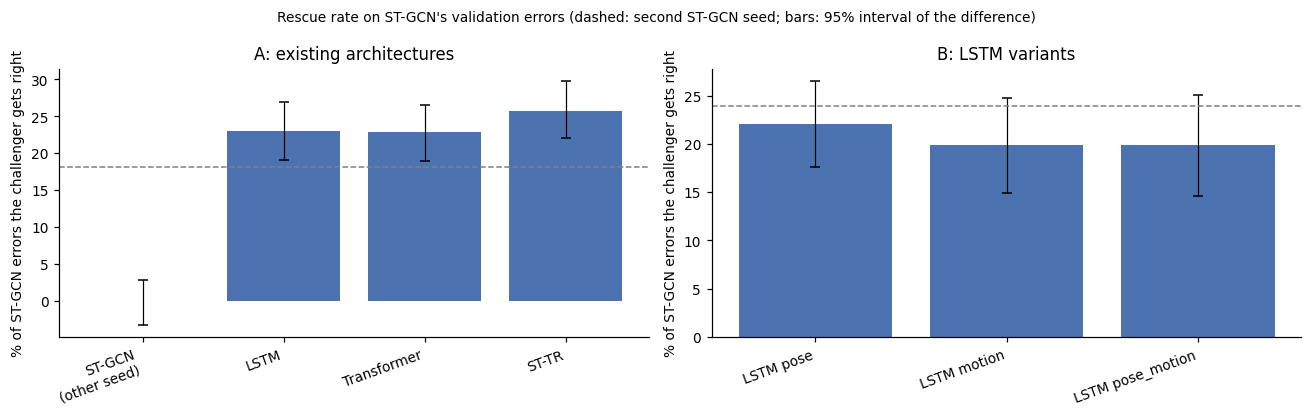

{'experiment': 'hybrid_diagnostics',
 'sequence_pathway_justified': False,
 'best_variant': 'LSTM pose',
 'rescue_difference_points': -1.93,
 'ci_points': [-6.34, 2.49],
 'rule': {'min_margin_points': 5.0, 'interval_above_zero': True}}

In [9]:
best = part_b.loc[part_b["difference"].idxmax()]
justified = bool(best["difference"] >= MIN_MARGIN and best["ci_lo"] > 0)
print(f"best variant: {best['challenger']}, rescue difference {100 * best['difference']:+.1f} points "
      f"[{100 * best['ci_lo']:+.1f}, {100 * best['ci_hi']:+.1f}] against the control")
print("rule (difference >= 5 points and interval above zero):", "PASSED, a sequence pathway is worth building and testing"
      if justified else "NOT PASSED, no complementary signal beyond what a second ST-GCN seed gives")

task = Task.init(project_name=PROJECT, task_name="hybrid_diagnostics_summary", task_type=Task.TaskTypes.qc,
                 tags=["hybrid_diagnostics", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({**RECIPE, "tuning_seeds": TUNING_SEEDS, "reporting_seeds": REPORTING_SEEDS, "bootstrap": N_BOOT,
              "rule": {"min_margin": MIN_MARGIN, "interval_above_zero": True}})
slog.report_table("part A: existing architectures (validation)", "val", iteration=0, table_plot=part_a_show)
slog.report_table("part B: LSTM variants (validation)", "val", iteration=0, table_plot=part_b_show)
slog.report_table("part B: LSTM variant accuracy (validation)", "val", iteration=0, table_plot=accuracy_b.reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, table, title in zip(axes, (part_a, part_b), ("A: existing architectures", "B: LSTM variants")):
    names = list(table["challenger"])
    x = np.arange(len(names))
    ax.bar(x, 100 * table["rescue rate"], color=["#b0b0b0" if "control" in n else "#4c72b0" for n in names])
    ax.errorbar(x, 100 * (table["control rescue rate"] + table["difference"]),
                yerr=[100 * (table["difference"] - table["ci_lo"]), 100 * (table["ci_hi"] - table["difference"])],
                fmt="none", color="black", capsize=3, lw=0.8)
    ax.axhline(100 * table["control rescue rate"].mean(), color="grey", ls="--", lw=1)
    ax.set_xticks(x, [n.replace(", other seed (control)", "\n(other seed)") for n in names], rotation=20, ha="right")
    ax.set_ylabel("% of ST-GCN errors the challenger gets right")
    ax.set_title(title)
fig.suptitle("Rescue rate on ST-GCN's validation errors (dashed: second ST-GCN seed; bars: 95% interval of the difference)", fontsize=9)
fig.tight_layout()
slog.report_matplotlib_figure("rescue rates", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

decision = {"experiment": "hybrid_diagnostics", "sequence_pathway_justified": justified, "best_variant": best["challenger"],
            "rescue_difference_points": round(100 * float(best["difference"]), 2),
            "ci_points": [round(100 * float(best["ci_lo"]), 2), round(100 * float(best["ci_hi"]), 2)],
            "rule": {"min_margin_points": 100 * MIN_MARGIN, "interval_above_zero": True}}
with open(f"{REPO}/configs/hybrid_diagnostics.json", "w") as f:
    json.dump(decision, f, indent=2)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/hybrid_diagnostics.json")
task.upload_artifact("results", artifact_object=results_path)
task.close()
decision

## Reading the result

- **If the rule passes**, a sequence pathway sees something the ST-GCN misses, and the next step is a two pathway
  network built around the variant that passed (with an auxiliary loss per pathway so that neither dominates),
  compared with the ST-GCN with velocity on validation and ablated one pathway at a time.
- **If it does not pass**, adding a sequence model offers nothing beyond seed diversity, and a hybrid of this kind would be
  an ensemble in disguise with no gain to find. The ST-GCN would then be shown to be near the ceiling for what these
  pose inputs support, which is a result in its own right, and the next design should change the *input*
  representation rather than the network.
- **Part A against part B.** If part A shows a clearly higher rescue rate for one existing architecture than for the
  control, that architecture is the one to use as the second pathway.
- **Caveats.** Validation has been used in every stage, rescue rates rest on a few hundred error clips, and the
  union accuracy is an oracle ceiling (it assumes the right model is picked for every clip), not an achievable score.